*Previous notebook: the dataset setup, why we normalise, weight initialisation, the baseline network and the bias/variance diagnosis. — This notebook: log loss (cross-entropy) as cost function.*

---

# Logistic Regression as Cost Function

Instead of using Mean Squared Error (MSE), logistic regression typically uses a different cost function called **log loss** (or **cross-entropy loss**), which allows for faster and more reliable learning in classification problems.

## Why is it faster?

MSE can slow down learning in classification tasks because it leads to **non-convex optimization problems** when combined with a sigmoid activation function. This means:
- The loss function may have multiple local minima
- Gradient descent can get stuck or converge slowly

In contrast, **log loss** produces a **convex cost function** for logistic regression:
- There is a single global minimum
- Gradient descent converges more efficiently
- Updates are more informative, especially when predictions are very wrong

Additionally, log loss penalizes confident wrong predictions **much more strongly**, which accelerates learning.

## How does it work? (Math Formula)

For a binary classification problem, logistic regression uses the **sigmoid function**:

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

where:

$$
z = w^T x + b
$$

The **log loss (cross-entropy)** cost function is:

$$
J(w, b) = -\frac{1}{m} \sum_{i=1}^{m} \left[ y^{(i)} \log(\hat{y}^{(i)}) + (1 - y^{(i)}) \log(1 - \hat{y}^{(i)}) \right]
$$

where:
- $m$ = number of training examples  
- $y^{(i)}$ = true label  
- $\hat{y}^{(i)} = \sigma(z^{(i)})$ = predicted probability  

## Graph (Intuition vs MSE)

To understand why log loss learns faster than MSE, compare their shapes:

- **MSE Loss**:
  - Has a flatter gradient when predictions are very wrong
  - Learning slows down because gradients become small

- **Log Loss**:
  - Very steep when predictions are wrong
  - Produces large gradients → faster correction

If the model predicts a probability close to 0 for a true label of 1, MSE gives a moderate penalty, Log loss gives a **huge penalty**, forcing rapid adjustment.
This is why logistic regression "learns faster": it **pushes strongly against wrong confident predictions**.

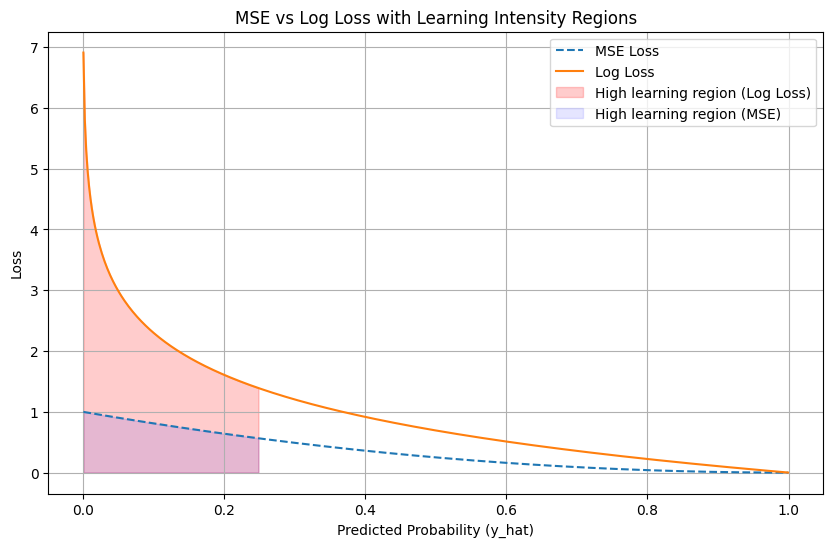

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Predicted probabilities
y_hat = np.linspace(0.001, 0.999, 500)  # avoid log(0)

# True label
y = 1

# Loss functions
mse = (y - y_hat) ** 2
log_loss = -(y * np.log(y_hat) + (1 - y) * np.log(1 - y_hat))

# Gradients (magnitude = how fast it learns)
grad_mse = np.abs(-2 * (y - y_hat))
grad_log = np.abs(-(y / y_hat) + ((1 - y) / (1 - y_hat)))

# Plot
plt.figure(figsize=(10, 6))

# Loss curves
plt.plot(y_hat, mse, label="MSE Loss", linestyle="--")
plt.plot(y_hat, log_loss, label="Log Loss")

# Highlight regions where learning is strong (high gradient)
threshold = np.percentile(grad_log, 75)

high_learning_region = grad_log > threshold

plt.fill_between(
    y_hat,
    log_loss,
    where=high_learning_region,
    color="red",
    alpha=0.2,
    label="High learning region (Log Loss)"
)

plt.fill_between(
    y_hat,
    mse,
    where=grad_mse > np.percentile(grad_mse, 75),
    color="blue",
    alpha=0.1,
    label="High learning region (MSE)"
)

# Labels
plt.title("MSE vs Log Loss with Learning Intensity Regions")
plt.xlabel("Predicted Probability (y_hat)")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

In [2]:
# Code for logistic regression cost 
import numpy as np

def log_loss(y, y_hat):
    """
    Compute the binary cross-entropy (log loss).

    Parameters
    ----------
    y : np.ndarray of shape (m,) or (m, 1)
        True binary labels (0 or 1)

    y_hat : np.ndarray of shape (m,) or (m, 1)
        Predicted probabilities (values in (0, 1))

    Returns
    -------
    float
        Mean log loss over all samples
    """
    
    # Flatten if needed
    if y.ndim == 2:
        assert y.shape[1] == 1, "y must have shape (m,) or (m, 1)"
        y = y.reshape(-1)
    if y_hat.ndim == 2:
        assert y_hat.shape[1] == 1, "y_hat must have shape (m,) or (m, 1)"
        y_hat = y_hat.reshape(-1)

    # Check matching shapes
    assert y.shape == y_hat.shape, "y and y_hat must have the same shape"

    # Numerical stability (avoid log(0))
    eps = 1e-15
    y_hat = np.clip(y_hat, eps, 1 - eps)

    # Log loss formula
    loss = -np.mean(
        y * np.log(y_hat) +
        (1 - y) * np.log(1 - y_hat)
    )

    return loss